# Split 70:30 
# Train with RFC and analyse performance
# Compare performance against a two models: 
#    - one that guesses randomly 
#    - another that always return "No".
# Hyperparameter Tuning ?? 5-fold cross-validation.


In [123]:
import os
import re
import random
import joblib
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
)
from sklearn.ensemble import RandomForestClassifier

## 1. Load the dataset

In [126]:
path = Path.cwd()
data_path = path.parent / "data"
model_path = path.parent / "models"

# Input: featurised 
input_path = data_path / "csic_2010_featurised.parquet" 

# Output: model
output_path = model_path / "model.joblib" 

In [104]:
# Load the featurised dataset
%time
df_featurised = pd.read_parquet(input_path)

CPU times: user 10 μs, sys: 1 μs, total: 11 μs
Wall time: 26.2 μs


In [105]:
df_featurised.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61065 entries, 0 to 61064
Data columns (total 20 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   contentLength                  61065 non-null  float64
 1   method_GET                     61065 non-null  float64
 2   method_POST                    61065 non-null  float64
 3   method_PUT                     61065 non-null  float64
 4   host_localhost:8080            61065 non-null  float64
 5   host_localhost:9090            61065 non-null  float64
 6   url_has_select                 61065 non-null  int64  
 7   url_has_drop                   61065 non-null  int64  
 8   url_has_numeric_id             61065 non-null  int64  
 9   url_length                     61065 non-null  int64  
 10  payload_quote_count            61065 non-null  int64  
 11  payload_paren_count            61065 non-null  int64  
 12  payload_slash_count            61065 non-null 

## 2. Split data into train/test

Identiy Training Input and Target Columns

In [143]:
#numeric_cols = df_featurised.select_dtypes(include=np.number).columns.tolist()
train_cols = list(df_featurised.columns)[0:-1]
print(train_cols)

['contentLength', 'method_GET', 'method_POST', 'method_PUT', 'host_localhost:8080', 'host_localhost:9090', 'url_has_select', 'url_has_drop', 'url_has_numeric_id', 'url_length', 'payload_quote_count', 'payload_paren_count', 'payload_slash_count', 'payload_parameter_count', 'payload_percent_count', 'payload_percent_encoded_count', 'payload_length', 'is_17_to_32_bytes', 'is_empty_payload']


In [146]:
#print(len(numeric_cols))
#print(numeric_cols)
# All columns except the last one (`anomalous` which is the target column) are training columns 
#train_cols = numeric_cols[0:-1]
# print(len(train_cols))
#print(train_cols)
# The Last column `anomalous` is the target column
#target_col = numeric_cols[-1]
target_col = 'anomalous' 
#print(len(target_col))
print(target_col)

anomalous


Using the Train and Target columns prepare training and target dataset

In [148]:
# Train dataset
df_train = df_featurised[train_cols]
df_train

,contentLength,method_GET,method_POST,method_PUT,host_localhost:8080,host_localhost:9090,url_has_select,url_has_drop,url_has_numeric_id,url_length,payload_quote_count,payload_paren_count,payload_slash_count,payload_parameter_count,payload_percent_count,payload_percent_encoded_count,payload_length,is_17_to_32_bytes,is_empty_payload
0,0.0,1.0,0.0,0.0,1.0,0.0,0,0,0,44,0,0,0,0,0,0,0,0,1
1,0.0,1.0,0.0,0.0,1.0,0.0,0,0,0,70,0,0,0,0,0,0,0,0,1
2,0.0,1.0,0.0,0.0,1.0,0.0,0,0,0,57,0,0,0,1,0,0,4,0,1
3,0.0,1.0,0.0,0.0,1.0,0.0,0,0,0,48,0,0,0,1,4,4,77,0,1
4,174.0,0.0,1.0,0.0,1.0,0.0,0,0,0,57,2,0,5,1,18,18,174,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61060,33.0,0.0,1.0,0.0,1.0,0.0,0,0,0,48,0,0,0,1,0,0,33,0,0
61061,248.0,0.0,1.0,0.0,1.0,0.0,0,0,0,49,0,0,0,1,3,3,248,0,0
61062,0.0,1.0,0.0,0.0,1.0,0.0,0,0,0,52,0,0,0,1,0,0,58,0,1
61063,38.0,0.0,1.0,0.0,1.0,0.0,0,0,0,47,0,0,0,1,0,0,38,0,0


In [149]:
# Target dataset
df_target = df_featurised[target_col]
df_target

0        0
1        1
2        0
3        1
4        1
        ..
61060    0
61061    1
61062    1
61063    0
61064    0
Name: anomalous, Length: 61065, dtype: int64

Split the training and targets in 70:30 ratio (70% for training and 30% for testing)

In [150]:
# Use train_test_split with stratification
test_size = 0.3 # 70:30 
random_state = 42 # Const seed
input_train, input_test, output_train, output_test = train_test_split(
    df_train, # X
    df_target, # y
    test_size=test_size,
    stratify=df_target, # y
    random_state=random_state,
)

> `test_size=0.3` implies `30%` of the dataset for testing, leaving `70%` for training.  
> The dataset is imbalanced, `stratify` ensures that the split maintains the same proportion of classes (`anom` / `norm`) as in the full dataset.  
> `input_train` and `output_train` represent the resulting **70% training and target feature data subset** respectively  
> `input_test` and `output_test` represent the resulting **30% testing and target feature data subset** respectively  


In [155]:
print(f"input_train: {input_train.shape}")
print(f"output_train: {input_train.shape}")

input_train: (42745, 19)
output_train: (42745, 19)


In [156]:
print(f"input_test: {input_test.shape}")
print(f"output_test: {input_test.shape}")

input_test: (18320, 19)
output_test: (18320, 19)


## 3. Train the baseline model with `RandomForestClassifier` default hyperparameters:

In [161]:
# n_estimators=100
# max_depth=10
#random_state=42
#model = RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth, random_state=random_state,)
model = RandomForestClassifier(random_state=42)
model.fit(input_train, output_train.values.ravel())

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

Check the feature importance

In [164]:
# Sort features by importance (descending order)
sorted_indices = model.feature_importances_.argsort()[::-1]  # [::-1] reverses the order to get descending
sorted_features = [train_cols[i] for i in sorted_indices]
sorted_importances = model.feature_importances_[sorted_indices]

# Print feature importances in sorted order
print("Feature Importances (Sorted):")
for feature, importance in zip(sorted_features, sorted_importances):
    print(f"    {feature}: {importance:.4f}")

Feature Importances (Sorted):
    payload_length: 0.2857
    url_length: 0.2749
    payload_percent_count: 0.1135
    payload_percent_encoded_count: 0.0994
    contentLength: 0.0794
    url_has_numeric_id: 0.0362
    payload_quote_count: 0.0327
    payload_parameter_count: 0.0297
    payload_slash_count: 0.0188
    method_PUT: 0.0046
    payload_paren_count: 0.0041
    host_localhost:9090: 0.0038
    host_localhost:8080: 0.0037
    is_17_to_32_bytes: 0.0035
    method_GET: 0.0034
    method_POST: 0.0032
    is_empty_payload: 0.0025
    url_has_select: 0.0006
    url_has_drop: 0.0003


**Observations:**  
- Features with high imortance  (Importance >= 0.05): `payload_length(`, `url_length`, `payload_percent_count`, `payload_percent_encoded_count`, `contentLength`
- Features with moderate importance (0.01 <= Importance < 0.05): `url_has_numeric_id`, `payload_quote_count`, `payload_parameter_count`, `payload_slash_count`
- Features with low importance (Importance < 0.01): `method_PUT`, `payload_paren_count`, `host_localhost:9090`, `host_localhost:8080`, `is_17_to_32_bytes`, `method_GET`, `method_POST`, `is_empty_payload`, `url_has_select`, `url_has_drop`

**Enhancement:** Focus on the most predictive features to improve model efficiency and performance.

In [165]:
#joblib.dump(model, output_path)
#print(f"model_saved={model_path}")

In [168]:
preds = model.predict(input_test)
proba = model.predict_proba(input_test)[:, 1]

In [204]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    precision_recall_curve, average_precision_score
)
from collections import Counter

# Compute metrics
tn, fp, fn, tp = confusion_matrix(output_test, preds).ravel()
precision, recall, _ = precision_recall_curve(output_test, proba)
avg_precision = average_precision_score(output_test, proba)
class_counts = Counter(output_test)

metrics = {
    "accuracy": round(float(accuracy_score(output_test, preds)), 6),
    "precision": round(float(precision_score(output_test, preds, zero_division=0)), 6),
    "recall": round(float(recall_score(output_test, preds, zero_division=0)), 6),
    "f1": round(float(f1_score(output_test, preds, zero_division=0)), 6),
    "roc_auc": round(float(roc_auc_score(output_test, proba)), 6),
    "average_precision": round(float(avg_precision), 6),
    "fpr": round(fp / (fp + tn), 6),  # False Positive Rate
    "fnr": round(fn / (fn + tp), 6),  # False Negative Rate
    #"confusion_matrix": confusion_matrix(output_test, preds).tolist(),
    #"confusion_matrix": confusion_matrix(output_test, preds, normalize='true'),
    "confusion_matrix": confusion_matrix(output_test, preds),
    "classification_report": classification_report(output_test, preds, zero_division=0),
    "class_imbalance_ratio": round(class_counts[0] / class_counts[1], 2),  # norm/anom ratio
    "n_test": int(len(input_test)),
}

# print("Model Performence metrics")
# print(f"Accuracy:          {round(accuracy_score(y_test, preds), 6):.6f}")
# print(f"Precision:         {round(precision_score(y_test, preds, zero_division=0), 6):.6f}")
# print(f"Recall:            {round(recall_score(y_test, preds, zero_division=0), 6):.6f}")
# print(f"F1-Score:          {round(f1_score(y_test, preds, zero_division=0), 6):.6f}")
# print(f"ROC-AUC:           {round(roc_auc_score(y_test, proba), 6):.6f}")
# print(f"Average Precision: {round(avg_precision, 6):.6f}")
# print(f"False Positive Rate: {round(fp / (fp + tn), 6):.6f}")
# print(f"False Negative Rate: {round(fn / (fn + tp), 6):.6f}")
# print(f"Class Imbalance Ratio (norm/anom): {round(class_counts[0] / class_counts[1], 2):.2f}")
# print(f"Test Samples:      {len(X_test)}")

# Model Performence metrics
# Accuracy:          0.872544
# Precision:         0.891321
# Recall:            0.785239
# F1-Score:          0.834924
# ROC-AUC:           0.945730
# Average Precision: 0.939055
# False Positive Rate: 0.066667
# False Negative Rate: 0.214761
# Class Imbalance Ratio (norm/anom): 1.44
# Test Samples:      18320


In [205]:
import json
# print("Model Performence metrics")
# print(f"Accuracy:          {metrics['accuracy']:.6f}")
# print(f"Precision:         {metrics['precision']:.6f}")
# print(f"Recall:            {metrics['recall']:.6f}")
# print(f"F1-Score:          {metrics['f1']:.6f}")
# print(f"ROC-AUC:           {metrics['roc_auc']:.6f}")
# print(f"Average Precision: {metrics['average_precision']:.6f}")
# print(f"False Positive Rate: {metrics['fpr']:.6f}")
# print(f"False Negative Rate: {metrics['fnr']:.6f}")

#print(f"Class Imbalance Ratio (norm/anom): {round(class_counts[0] / class_counts[1], 2):.2f}")
#print(f"Test Samples:      {len(X_test)}")
# print("Metrics Report:")
# print(json.dumps(metrics, indent=2))
# print("")
print("Confusion Matrix:")
print(metrics["confusion_matrix"])
print("Classification Report:")
print(metrics["classification_report"])

Confusion Matrix:
[[10111   689]
 [ 1448  6072]]
Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.94      0.90     10800
           1       0.90      0.81      0.85      7520

    accuracy                           0.88     18320
   macro avg       0.89      0.87      0.88     18320
weighted avg       0.88      0.88      0.88     18320



[[0.9362037  0.0637963 ]
 [0.19255319 0.80744681]]


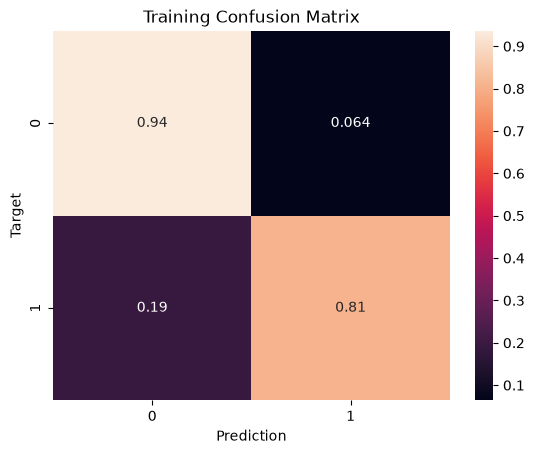

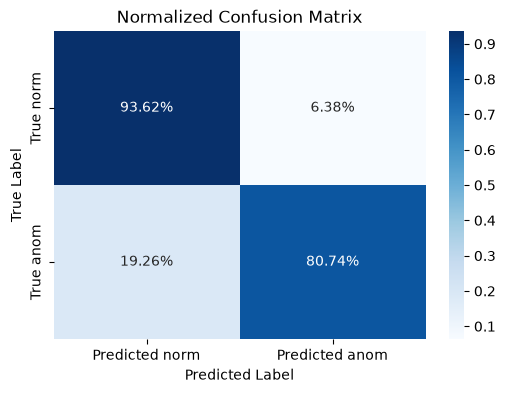

In [207]:
#import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns
# %matplotlib inline
plt.figure()
cm = confusion_matrix(output_test, preds, normalize='true')
print(cm)
sns.heatmap(cm, annot=True)
plt.xlabel('Prediction')
plt.ylabel('Target')
plt.title('Training Confusion Matrix');

# Compute normalized confusion matrix
cm_normalized = confusion_matrix(output_test, preds, normalize='true')

# Plot
plt.figure(figsize=(6, 4))
sns.heatmap(cm_normalized, annot=True, fmt=".2%", cmap="Blues",
            xticklabels=["Predicted norm", "Predicted anom"],
            yticklabels=["True norm", "True anom"])
plt.title("Normalized Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
#plt.savefig('normalized_confusion_matrix.png', format='PNG', dpi=200, bbox_inches='tight')
plt.show()

# # cm = metrics['confusion_matrix']
# cm = confusion_matrix(output_test, preds)
# fig, ax = plt.subplots(figsize=(4, 4))
# ax.imshow(cm, cmap="Blues")
# for i in range(cm.shape[0]):
#     for j in range(cm.shape[1]):
#         ax.text(j, i, str(cm[i, j]), ha="center", va="center", color="black")
# ax.set_xlabel("predicted")
# ax.set_ylabel("actual")
# ax.set_title("confusion matrix")
# fig.tight_layout()
# #fig.savefig(path, dpi=100)


In [170]:
print("Model Performence metrics")
print(f"Accuracy:          {round(accuracy_score(y_test, preds), 6):.6f}")
print(f"Precision:         {round(precision_score(y_test, preds, zero_division=0), 6):.6f}")
print(f"Recall:            {round(recall_score(y_test, preds, zero_division=0), 6):.6f}")
print(f"F1-Score:          {round(f1_score(y_test, preds, zero_division=0), 6):.6f}")
print(f"ROC-AUC:           {round(roc_auc_score(y_test, proba), 6):.6f}")
print(f"Average Precision: {round(avg_precision, 6):.6f}")
print(f"False Positive Rate: {round(fp / (fp + tn), 6):.6f}")
print(f"False Negative Rate: {round(fn / (fn + tp), 6):.6f}")
print(f"Class Imbalance Ratio (norm/anom): {round(class_counts[0] / class_counts[1], 2):.2f}")
print(f"Test Samples:      {len(X_test)}")

Model Performence metrics
Accuracy:          0.883352
Precision:         0.898092
Recall:            0.807447
F1-Score:          0.850361
ROC-AUC:           0.951669
Average Precision: 0.946433
False Positive Rate: 0.063796
False Negative Rate: 0.192553
Class Imbalance Ratio (norm/anom): 1.44
Test Samples:      18320


**Observations:**

TBD

## 4. Compare to dummy classifier

In [171]:
# Benchmark against `DummyClassifier(strategy="most_frequent")`

## 5. Compare to constant classifiers  

A **constant classifier** always predicts the same class (e.g., always `norm` or always `anom`). This is useful to see how the baseline model performs compared to always guessing the majority or minority class.

Always Predict `norm` (Majority Class)

In [ ]:
y_pred_constant_norm = [0] * len(output_test)  # 0 = norm, 1 = anom

# Compute metrics
metrics_constant_norm = {
    "accuracy": accuracy_score(output_test, y_pred_constant_norm),
    "precision": precision_score(output_test, y_pred_constant_norm, zero_division=0),
    "recall": recall_score(output_test, y_pred_constant_norm, zero_division=0),
    "f1": f1_score(output_test, y_pred_constant_norm, zero_division=0),
    "roc_auc": roc_auc_score(output_test, y_pred_constant_norm) if len(np.unique(output_test)) > 1 else 0.5,
}

print("Metrics for Constant Classifier (Always Predict norm):")
for metric, value in metrics_constant_norm.items():
    print(f"    {metric}: {value:.6f}")

## 6. `GridSearchCV` - Find the best hyperparameters using cross-validation. 

## 7. Cross-Validation

## 5. Log results

In [173]:
# Save metrics, confusion matrix, and classification report.